In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.decomposition import PCA

The dataset used in this study is the Bangladesh Crime Dataset, which contains information on crime incidents across different regions and time periods in Bangladesh. The dataset was imported using pandas, and a preliminary exploration was performed to examine the variables and data structure.

In [2]:
df = pd.read_csv("Bangladesh_Crime_Dataset_B.csv")
df.head()

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,0,7,29,wednesday,0,morning,dhaka,dhaka,6.1,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
1,1,1,2,wednesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
2,2,1,4,tuesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
3,3,3,9,friday,1,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
4,4,8,34,thursday,0,night,dhaka,dhaka,21.9,9,...,8.42,30551,74.6,4289,99,17,60,242,64,murder


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6574 entries, 0 to 6573
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              6574 non-null   int64  
 1   incident_month          6574 non-null   int64  
 2   incident_week           6574 non-null   int64  
 3   incident_weekday        6574 non-null   object 
 4   weekend                 6574 non-null   int64  
 5   part_of_the_day         6457 non-null   object 
 6   incident_district       6574 non-null   object 
 7   incident_division       6574 non-null   object 
 8   precip                  5917 non-null   float64
 9   visibility              6574 non-null   int64  
 10  heatindex               6574 non-null   int64  
 11  season                  6246 non-null   object 
 12  male_population         6574 non-null   int64  
 13  female_population       6574 non-null   int64  
 14  total_population        6574 non-null   

In [4]:
print("Before fill missing value")
df.isnull().sum()

Before fill missing value


Unnamed: 0                  0
incident_month              0
incident_week               0
incident_weekday            0
weekend                     0
part_of_the_day           117
incident_district           0
incident_division           0
precip                    657
visibility                  0
heatindex                   0
season                    328
male_population             0
female_population           0
total_population            0
gender_ration               0
average_household_size      0
density_per_kmsq            0
literacy_rate             328
religious_institution       0
playground                  0
park                        0
police_station              0
school                      0
college                     0
crime                       0
dtype: int64

From the result of the missing value check, it can be seen that most variables in the dataset did not have any missing data. However, there are several variables that still have missing values, namely part_of_the_day with 117 data, precip with 657 data, season with 328 data, and literacy_rate with 328 data. These missing values give an indication of incomplete information related to the time of the incident, weather conditions, the season, and also literacy levels in a number of regions. In this regard, the handling of missing values is necessary before using the data in further analysis, so that analysis results that are more accurate and free from bias can be produced.

In [5]:
df.drop(columns=['Unnamed: 0'], inplace=True)
df['part_of_the_day'].fillna(df['part_of_the_day'].mode()[0], inplace=True)
df['season'].fillna(df['season'].mode()[0], inplace=True)
df['precip'].fillna(df['precip'].median(), inplace=True)
df['literacy_rate'].fillna(df['literacy_rate'].median(), inplace=True)

C:\Users\olive\AppData\Local\Temp\ipykernel_27044\385572062.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['part_of_the_day'].fillna(df['part_of_the_day'].mode()[0], inplace=True)
C:\Users\olive\AppData\Local\Temp\ipykernel_27044\385572062.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always be

In the preprocessing stage, the Unnamed: 0 column was removed as it had no analytical significance. Next, missing values ​​in the categorical variables part_of_the_day and season were filled using the mode value because it appeared most frequently. Meanwhile, missing values ​​in the numeric variables precip and literacy_rate were filled using the median to reduce the influence of extreme values ​​and maintain the stability of the data distribution.


In [6]:
print("After fill missing value")
df.isnull().sum()

After fill missing value


incident_month            0
incident_week             0
incident_weekday          0
weekend                   0
part_of_the_day           0
incident_district         0
incident_division         0
precip                    0
visibility                0
heatindex                 0
season                    0
male_population           0
female_population         0
total_population          0
gender_ration             0
average_household_size    0
density_per_kmsq          0
literacy_rate             0
religious_institution     0
playground                0
park                      0
police_station            0
school                    0
college                   0
crime                     0
dtype: int64

In [7]:
df.describe()

,incident_month,incident_week,weekend,precip,visibility,heatindex,male_population,female_population,total_population,gender_ration,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college
count,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6.574000e+03,6.574000e+03,6.574000e+03,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000,6574.000000
mean,6.193185,25.193946,0.273806,5.603423,9.488287,31.597657,8.936342e+05,7.544586e+05,1.648104e+06,104.429723,4.965023,6362.512017,55.650745,1219.757073,42.504411,3.863706,11.762093,75.218893,15.479617
std,3.321934,14.517965,0.445944,11.288274,0.922742,5.502593,1.605205e+06,1.284180e+06,2.889245e+06,10.387173,1.422850,10368.342248,11.784014,1246.313725,44.857967,5.883186,19.604510,71.743767,19.721917
min,1.000000,1.000000,0.000000,0.000000,4.000000,15.000000,1.132000e+04,1.124700e+04,2.287100e+04,84.000000,3.580000,23.000000,26.700000,-99.000000,0.000000,0.000000,-1.000000,1.000000,0.000000
25%,3.000000,13.000000,0.000000,0.000000,9.000000,27.000000,1.319300e+05,1.339960e+05,2.652760e+05,98.000000,4.110000,924.000000,47.300000,509.500000,5.000000,0.000000,2.000000,30.000000,4.000000
50%,6.000000,25.000000,0.000000,0.800000,10.000000,33.000000,1.872290e+05,1.870170e+05,3.765500e+05,101.000000,4.440000,1239.000000,53.900000,797.000000,25.000000,1.000000,3.000000,45.000000,8.000000
75%,9.000000,37.000000,1.000000,6.175000,10.000000,36.000000,3.917070e+05,3.811572e+05,7.757330e+05,109.000000,5.100000,3977.000000,65.400000,1121.000000,78.000000,3.000000,6.000000,86.000000,15.000000
max,12.000000,53.000000,1.000000,204.600000,10.000000,43.000000,4.931802e+06,3.974237e+06,8.906039e+06,203.000000,8.420000,30551.000000,74.600000,4289.000000,253.000000,17.000000,74.000000,242.000000,64.000000


Descriptive statistics show that the dataset has significant variation in weather, demographics, and public facilities aspects, reflecting differences in characteristics between regions and time of occurrence.

**Exploratory Data Analysis**

In [8]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include='object').columns

**Correlation Heatmap of Numerical Features**

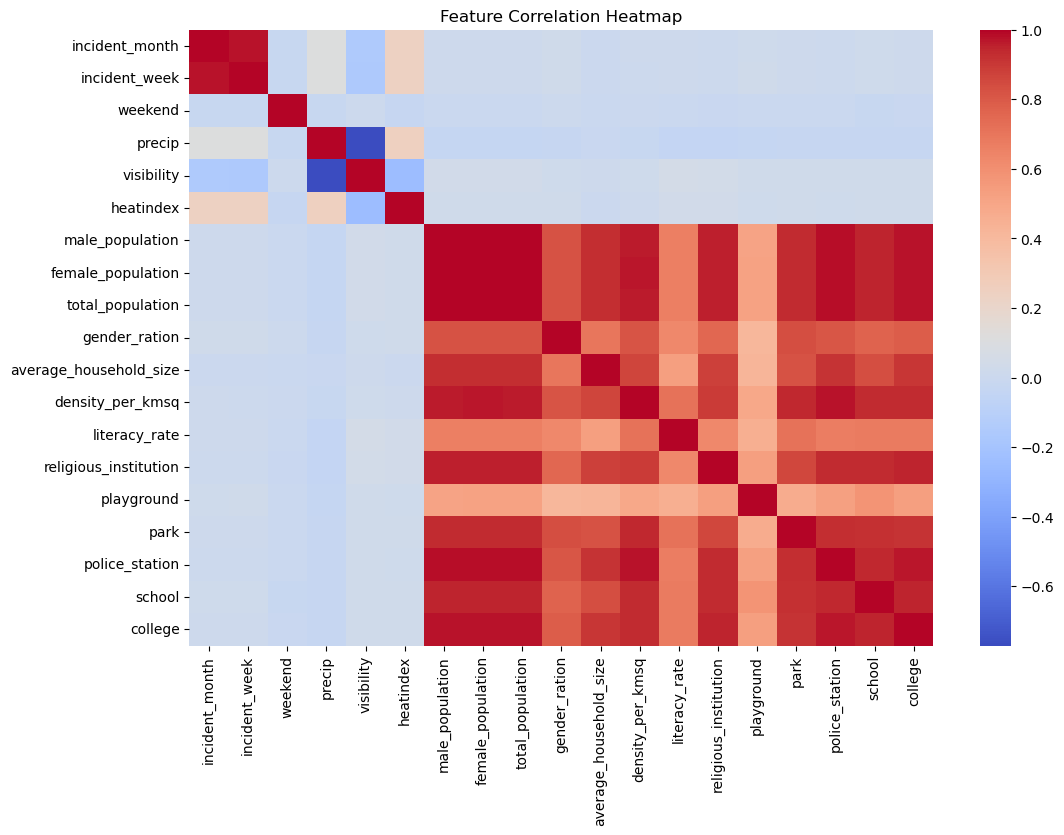

In [9]:
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

This is feature Correlation Heatmap that shows the relationship between variables in the dataset. A strong positive correlation is seen between population variables such as *male_population*, *female_population*, and *total_population*. Meanwhile, some weather variables such as *precip* and *visibility* show a negative correlation with other variables.


**Boxplot of Numerical Variable**

Text(0.5, 1.0, 'Boxplot of All Numerical Variables')

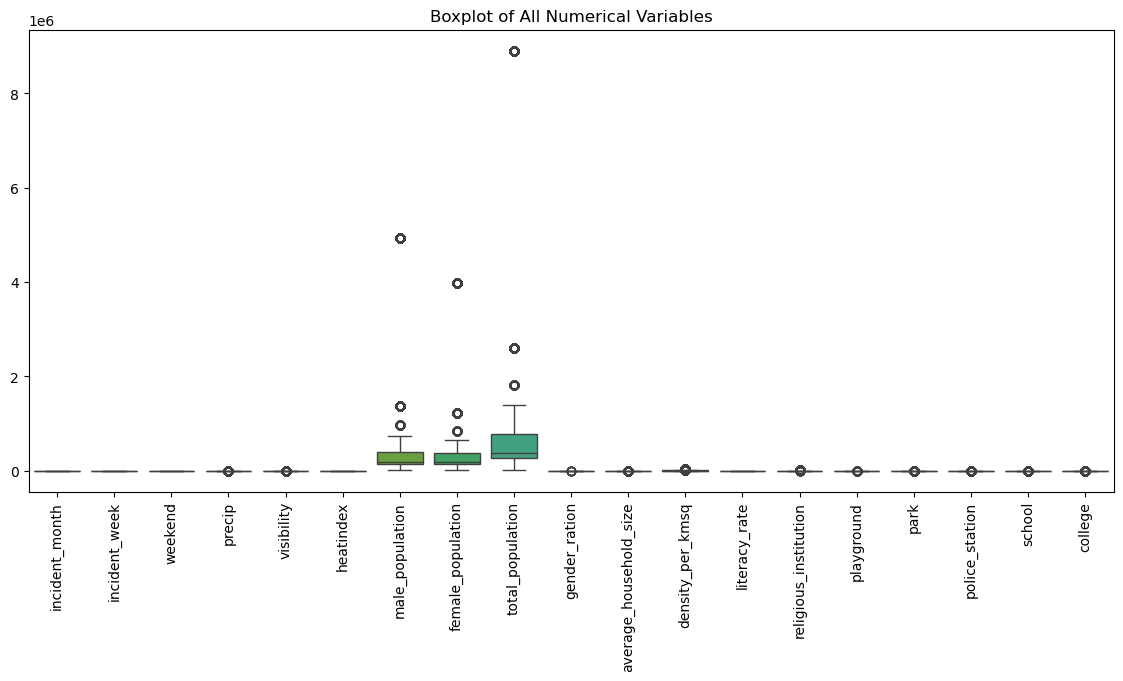

In [10]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df[num_cols])
plt.xticks(rotation=90)
plt.title("Boxplot of All Numerical Variables")

This is a Boxplot of All Numerical Variables, which displays the distribution of each numeric variable. Population variables such as male_population, female_population, and total_population have significantly larger values ​​than other variables. In contrast, variables such as precipitation, visibility, and heatindex show a smaller and more stable distribution.

In [11]:
df_clean = df.copy()

num_cols_clean = [
    'precip',
    'visibility',
    'heatindex',
    'average_household_size',
    'density_per_kmsq',
    'literacy_rate'
]

for col in num_cols_clean:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

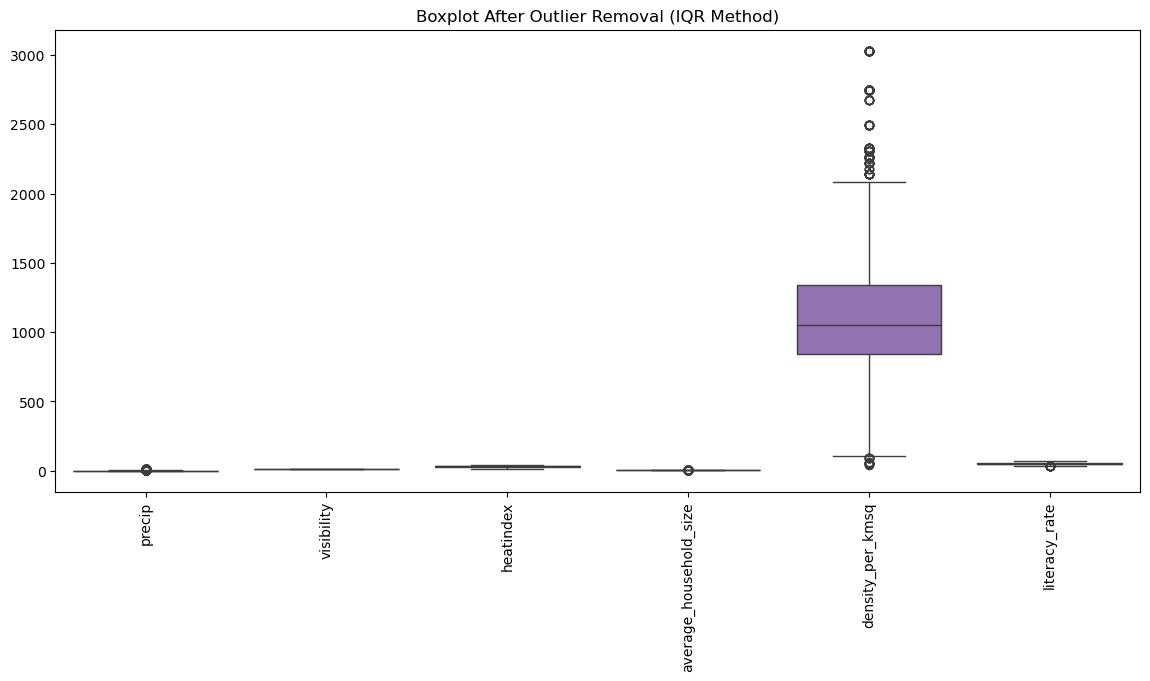

In [12]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df_clean[num_cols_clean])
plt.xticks(rotation=90)
plt.title("Boxplot After Outlier Removal (IQR Method)")
plt.show()

This is a Boxplot After Outlier Removal (IQR Method) showing the distribution of variables after outliers have been removed. Variables such as *precip*, *visibility*, and *heatindex* appear more stable and compact. Meanwhile, *density_per_kmsq* still shows a wide spread and several striking outliers.

**Crime Distribution by the Time of Day**

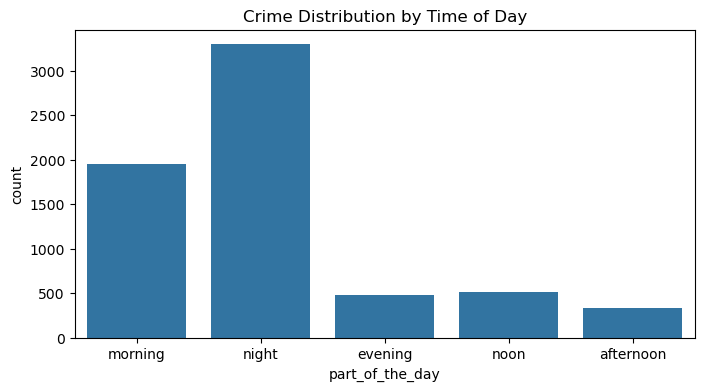

In [13]:
plt.figure(figsize=(8,4))
sns.countplot(x='part_of_the_day', data=df)
plt.title("Crime Distribution by Time of Day")
plt.show()

This is the Crime Distribution by Time of Day, which shows the number of crime incidents based on the time of day. It appears that evenings have the highest number of cases, followed by mornings. Meanwhile, midday, afternoon, and evening have significantly lower numbers.

**Crime Distribution**

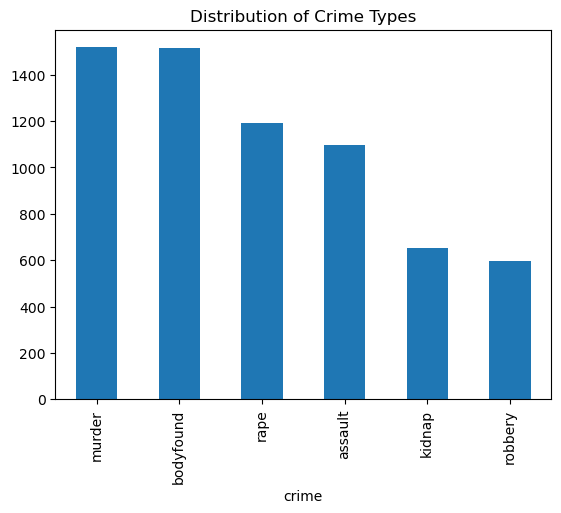

In [14]:
df['crime'].value_counts().plot(kind='bar')
plt.title("Distribution of Crime Types")
plt.show()

This is the Distribution of Crime Types, which shows the frequency of various types of crime. Murder and body found have the highest number of cases, approaching 1,500 each. Kidnapping and robbery are recorded as the types of crime with the lowest frequency.

**Crime Based on weekend and weekdays**

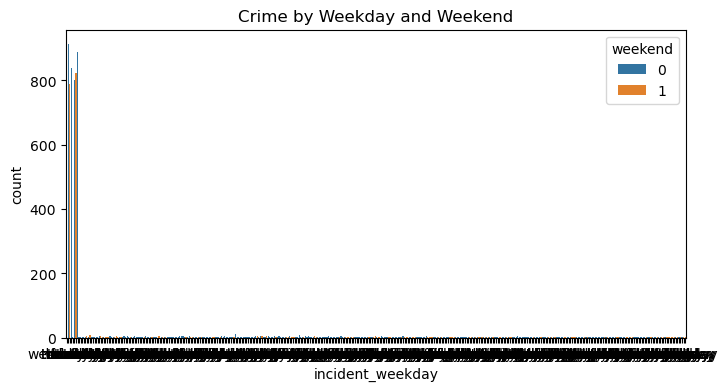

In [15]:
plt.figure(figsize=(8,4))
sns.countplot(x='incident_weekday', hue='weekend', data=df)
plt.title("Crime by Weekday and Weekend")
plt.show()

This is the Crime by Weekday and Weekend chart, which shows the number of crimes by day of the week. It can be seen that some days have significantly higher crime rates, particularly weekdays. The color difference in the bars indicates the division between weekdays and weekends.


**ScatterPlot of Density vs Total Population**

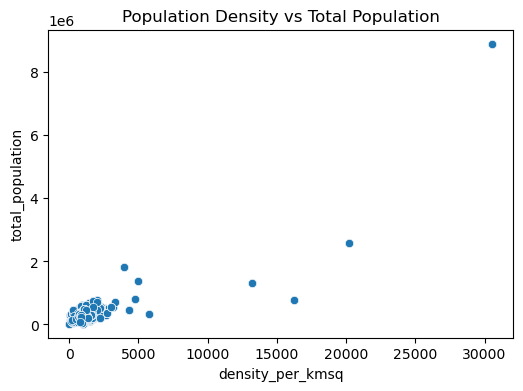

In [16]:
plt.figure(figsize=(6,4))
sns.scatterplot(x='density_per_kmsq', y='total_population', data=df)
plt.title("Population Density vs Total Population")
plt.show()

This is an indication of Population Density vs. Total Population, indicating the relationship between the two variables. Most of the data is concentrated in the lower range of the two variables, although there are some data points in the outer range. An illustrative point in this scatterplot is where the density is approximately 30,000 km and the population is close to 9 million.

Precipitation Distribution

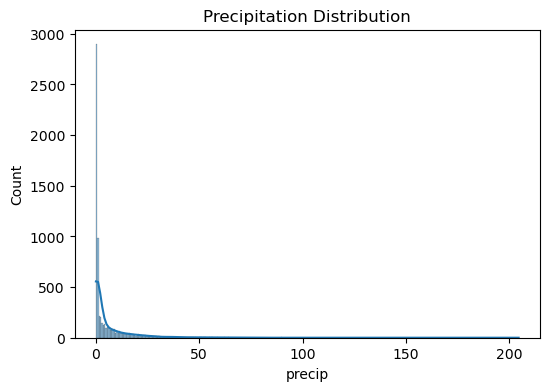

In [18]:
plt.figure(figsize=(6,4))
sns.histplot(df['precip'], kde=True)
plt.title("Precipitation Distribution")
plt.show()

This is the Precipitation Distribution, which shows the distribution of rainfall values ​​in the dataset. Most of the data is concentrated at low values, with the distribution skewed to the right. The density curve shows a sharp drop, indicating that high rainfall is relatively rare.


**Clustering model**

In [19]:
le = LabelEncoder()

cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

At this stage, the encoding process is carried out on all categorical variables using the Label Encoder, namely by changing the category values ​​in text form into numeric representations so that the data can be processed by the K-Means algorithm.

In [20]:
X = df.select_dtypes(include=['int64', 'float64'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

After all the data is in numeric form, a standardization process is carried out using StandardScaler to equalize the scale of each feature, so that no variable dominates the distance calculation in the K-Means algorithm.

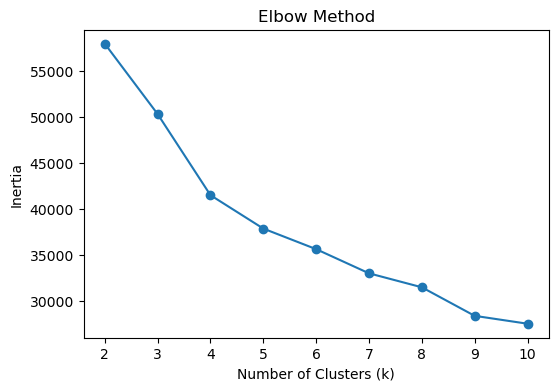

In [21]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(range(2,11), inertia, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

Based on the silhouette score evaluation, the best number of clusters was k = 2 with a value of 0.607, indicating good clustering quality. Increasing the number of clusters to 3, 4, and 5 actually decreased the silhouette score, resulting in less optimal cluster separation.

In [22]:
for k in range(2, 6):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    ch  = calinski_harabasz_score(X_scaled, labels)

    print(f"k={k} | Silhouette={sil:.3f} | Calinski-Harabasz={ch:.2f}")

k=2 | Silhouette=0.607 | Calinski-Harabasz=7582.90
k=3 | Silhouette=0.245 | Calinski-Harabasz=4865.04
k=4 | Silhouette=0.278 | Calinski-Harabasz=4395.50
k=5 | Silhouette=0.274 | Calinski-Harabasz=3768.74


The number of clusters was evaluated using two metrics: the Silhouette Score and the Calinski–Harabasz Index. The evaluation results showed that k = 2 produced the highest scores for both metrics, making this number of clusters the optimal one. Increasing the number of clusters actually decreased the quality of data separation.

In [23]:
kmeans = KMeans(n_clusters=4, random_state=42)
df['cluster_direct'] = kmeans.fit_predict(X_scaled)
df[['cluster_direct']].value_counts()

cluster_direct
1                 3068
3                 1938
2                  872
0                  696
Name: count, dtype: int64

The clustering results show that most of the data is concentrated in cluster 1, while the other clusters have smaller amounts of data. This indicates differences in characteristics between the data groups.

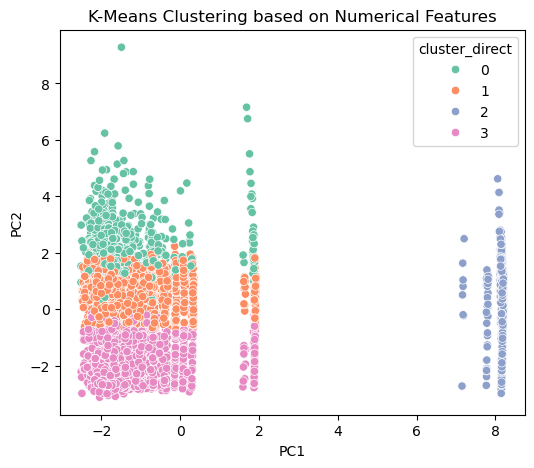

In [24]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(6,5))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=df['cluster_direct'],
    palette='Set2'
)
plt.title("K-Means Clustering based on Numerical Features")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

**Cluster Interpretation**

In [25]:
df.groupby('cluster_direct')[[
    'density_per_kmsq',
    'literacy_rate',
    'precip',
    'police_station'
]].mean()

,density_per_kmsq,literacy_rate,precip,police_station
cluster_direct,,,,
0,2692.988506,51.704167,28.726006,4.563218
1,2673.878422,53.262647,3.629140,4.331160
2,30551.000000,73.697936,4.617087,59.930046
3,2636.172859,52.728328,0.868576,4.438080


The clustering results show significant differences in regional characteristics. Cluster 2 represents an urban area with a significantly higher population density, literacy rate, and number of police stations than the other clusters. Meanwhile, clusters 0, 1, and 3 have relatively similar characteristics in terms of population density and facilities, with the main difference being rainfall levels.